In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C8"
DTYPE="G_H"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C8_10,30,"[DATA/TRAINING/C8/C8_10/IMG_8678.HEIC, DATA/TR..."
1,C8_11,25,"[DATA/TRAINING/C8/C8_11/IMG_8730.HEIC, DATA/TR..."
2,C8_12,25,"[DATA/TRAINING/C8/C8_12/IMG_8761.HEIC, DATA/TR..."
3,C8_13,25,"[DATA/TRAINING/C8/C8_13/IMG_8793.HEIC, DATA/TR..."
4,C8_14,25,"[DATA/TRAINING/C8/C8_14/IMG_8823.HEIC, DATA/TR..."
5,C8_15,26,"[DATA/TRAINING/C8/C8_15/IMG_8855.HEIC, DATA/TR..."
6,C8_16,25,"[DATA/TRAINING/C8/C8_16/IMG_8886.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

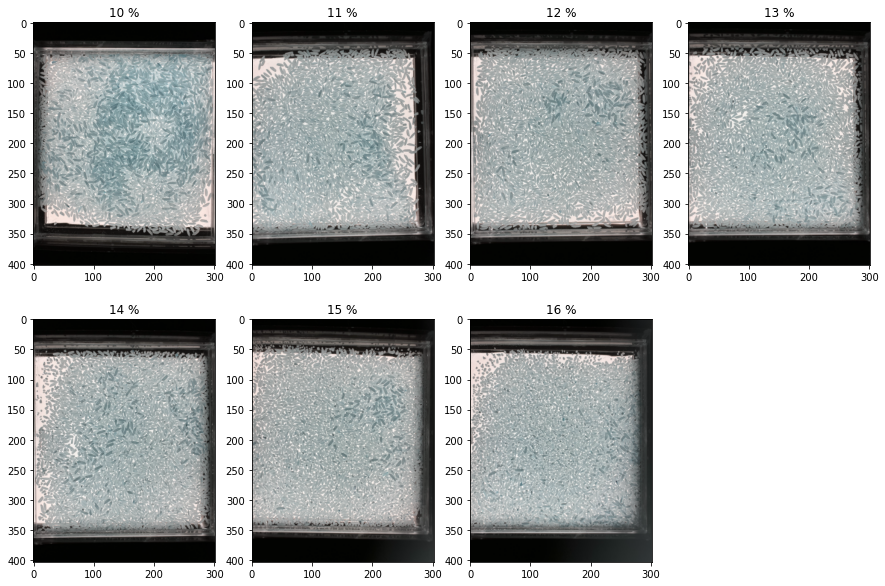

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [7]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [158]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [159]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/"; 
result.to_csv(DIR+'features_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.561799,0.042029,0.050897,0.066706,0.051669,0.045114,0.070562,0.038559,0.051283,0.060923,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8678.HEIC,10
1,0.561035,0.029330,0.063173,0.045876,0.027826,0.023314,0.039107,0.029330,0.033467,0.059037,...,0.000752,0.0,0.0,3,44,120,90,3,IMG_8679.HEIC,10
2,0.558231,0.041964,0.029259,0.031954,0.053898,0.048508,0.039654,0.035419,0.043504,0.047353,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8680.HEIC,10
3,0.563417,0.041490,0.033735,0.053511,0.042654,0.038001,0.031796,0.020939,0.013184,0.040715,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8682.HEIC,10
4,0.543622,0.035843,0.024269,0.056005,0.038083,0.047044,0.040697,0.023149,0.041817,0.047418,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8686.HEIC,10
5,0.527600,0.039042,0.037251,0.054802,0.054802,0.051578,0.039758,0.054085,0.064473,0.040474,...,0.000358,0.0,0.0,3,44,120,90,3,IMG_8693.HEIC,10
6,0.554030,0.031722,0.035780,0.052378,0.046108,0.037624,0.052009,0.066764,0.064920,0.043526,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8701.HEIC,10
7,0.567902,0.036529,0.062138,0.058748,0.054606,0.040672,0.054606,0.083227,0.073812,0.037659,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8702.HEIC,10
8,0.575624,0.017846,0.069485,0.083534,0.058474,0.043665,0.034173,0.037211,0.046703,0.030756,...,0.000380,0.0,0.0,3,44,120,90,3,IMG_8703.HEIC,10
9,0.559348,0.018008,0.029401,0.070194,0.051819,0.041161,0.037118,0.037853,0.052554,0.037118,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8704.HEIC,10


# Classification

In [160]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.561799,0.042029,0.050897,0.066706,0.051669,0.045114,0.070562,0.038559,0.051283,0.060923,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8678.HEIC,10
1,0.561035,0.029330,0.063173,0.045876,0.027826,0.023314,0.039107,0.029330,0.033467,0.059037,...,0.000752,0.0,0.0,3,44,120,90,3,IMG_8679.HEIC,10
2,0.558231,0.041964,0.029259,0.031954,0.053898,0.048508,0.039654,0.035419,0.043504,0.047353,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8680.HEIC,10
3,0.563417,0.041490,0.033735,0.053511,0.042654,0.038001,0.031796,0.020939,0.013184,0.040715,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8682.HEIC,10
4,0.543622,0.035843,0.024269,0.056005,0.038083,0.047044,0.040697,0.023149,0.041817,0.047418,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8686.HEIC,10
5,0.527600,0.039042,0.037251,0.054802,0.054802,0.051578,0.039758,0.054085,0.064473,0.040474,...,0.000358,0.0,0.0,3,44,120,90,3,IMG_8693.HEIC,10
6,0.554030,0.031722,0.035780,0.052378,0.046108,0.037624,0.052009,0.066764,0.064920,0.043526,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8701.HEIC,10
7,0.567902,0.036529,0.062138,0.058748,0.054606,0.040672,0.054606,0.083227,0.073812,0.037659,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8702.HEIC,10
8,0.575624,0.017846,0.069485,0.083534,0.058474,0.043665,0.034173,0.037211,0.046703,0.030756,...,0.000380,0.0,0.0,3,44,120,90,3,IMG_8703.HEIC,10
9,0.559348,0.018008,0.029401,0.070194,0.051819,0.041161,0.037118,0.037853,0.052554,0.037118,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8704.HEIC,10


In [161]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [162]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [163]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [164]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

### Random Forest Classifier

In [165]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [166]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.631579,0.630952,0.619048,0.624943,G_H,C8,RF_C,3,44,120,90,3
1,2,0.888889,0.928571,0.904762,0.916512,G_H,C8,RF_C,3,44,120,90,3
2,3,0.611111,0.607143,0.571429,0.588745,G_H,C8,RF_C,3,44,120,90,3
3,4,0.777778,0.918367,0.785714,0.846878,G_H,C8,RF_C,3,44,120,90,3
4,5,0.888889,0.904762,0.904762,0.904762,G_H,C8,RF_C,3,44,120,90,3
5,6,0.944444,0.964286,0.952381,0.958296,G_H,C8,RF_C,3,44,120,90,3
6,7,0.888889,0.916667,0.880952,0.898455,G_H,C8,RF_C,3,44,120,90,3
7,8,0.722222,0.750000,0.714286,0.731707,G_H,C8,RF_C,3,44,120,90,3
8,9,0.722222,0.795238,0.761905,0.778215,G_H,C8,RF_C,3,44,120,90,3
9,10,0.611111,0.702381,0.642857,0.671302,G_H,C8,RF_C,3,44,120,90,3


In [167]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C8,RF_C,0.768713,0.77381,0.791981,0.811837


### MLP Classifier

In [168]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [169]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [170]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.789474,0.773810,0.761905,0.767811,G_H,C8,MLP_C,3,44,120,90,3
1,2,0.722222,0.752381,0.714286,0.732839,G_H,C8,MLP_C,3,44,120,90,3
2,3,0.833333,0.845238,0.833333,0.839243,G_H,C8,MLP_C,3,44,120,90,3
3,4,0.833333,0.833333,0.833333,0.833333,G_H,C8,MLP_C,3,44,120,90,3
4,5,0.777778,0.823810,0.785714,0.804311,G_H,C8,MLP_C,3,44,120,90,3
5,6,1.000000,1.000000,1.000000,1.000000,G_H,C8,MLP_C,3,44,120,90,3
6,7,0.888889,0.916667,0.880952,0.898455,G_H,C8,MLP_C,3,44,120,90,3
7,8,0.777778,0.845238,0.809524,0.826996,G_H,C8,MLP_C,3,44,120,90,3
8,9,0.944444,0.952381,0.952381,0.952381,G_H,C8,MLP_C,3,44,120,90,3
9,10,0.833333,0.845238,0.833333,0.839243,G_H,C8,MLP_C,3,44,120,90,3


In [171]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C8,MLP_C,0.840058,0.840476,0.849461,0.85881


### XGBoost Classifier

In [172]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [173]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.789474,0.857143,0.785714,0.819876,G_H,C8,XGB_C,3,44,120,90,3
1,2,0.833333,0.880952,0.833333,0.856481,G_H,C8,XGB_C,3,44,120,90,3
2,3,0.833333,0.845238,0.833333,0.839243,G_H,C8,XGB_C,3,44,120,90,3
3,4,0.888889,0.942857,0.880952,0.910854,G_H,C8,XGB_C,3,44,120,90,3
4,5,0.777778,0.880952,0.761905,0.817115,G_H,C8,XGB_C,3,44,120,90,3
5,6,0.722222,0.761905,0.714286,0.737327,G_H,C8,XGB_C,3,44,120,90,3
6,7,0.833333,0.880952,0.857143,0.868885,G_H,C8,XGB_C,3,44,120,90,3
7,8,0.944444,0.952381,0.952381,0.952381,G_H,C8,XGB_C,3,44,120,90,3
8,9,0.888889,0.942857,0.880952,0.910854,G_H,C8,XGB_C,3,44,120,90,3
9,10,0.888889,0.916667,0.904762,0.910675,G_H,C8,XGB_C,3,44,120,90,3


In [174]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C8,XGB_C,0.840058,0.840476,0.862369,0.88619


# External validation


In [175]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C8_10,5,"[DATA/TEST/C8/C8_10/IMG_8685.HEIC, DATA/TEST/C..."
1,C8_11,5,"[DATA/TEST/C8/C8_11/IMG_8732.HEIC, DATA/TEST/C..."
2,C8_12,5,"[DATA/TEST/C8/C8_12/IMG_8762.HEIC, DATA/TEST/C..."
3,C8_13,5,"[DATA/TEST/C8/C8_13/IMG_8792.HEIC, DATA/TEST/C..."
4,C8_14,5,"[DATA/TEST/C8/C8_14/IMG_8827.HEIC, DATA/TEST/C..."
5,C8_15,5,"[DATA/TEST/C8/C8_15/IMG_8854.HEIC, DATA/TEST/C..."
6,C8_16,5,"[DATA/TEST/C8/C8_16/IMG_8901.HEIC, DATA/TEST/C..."


In [176]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [177]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [178]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.569986,0.040013,0.032559,0.039621,0.063942,0.047074,0.039228,0.024321,0.028244,0.040013,...,0.000785,0.0,0.0,3,44,120,90,3,IMG_8685.HEIC,10
1,0.532639,0.033721,0.026831,0.055113,0.039159,0.034083,0.032995,0.031182,0.041335,0.038797,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8687.HEIC,10
2,0.522132,0.041714,0.023332,0.036765,0.044542,0.041360,0.035351,0.035351,0.049845,0.052673,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8688.HEIC,10
3,0.564332,0.054436,0.028197,0.061877,0.075584,0.078717,0.046212,0.063052,0.046603,0.042296,...,0.000392,0.0,0.0,3,44,120,90,3,IMG_8696.HEIC,10
4,0.518339,0.027067,0.029774,0.055150,0.044661,0.030451,0.024699,0.035864,0.040939,0.034511,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8699.HEIC,10
0,0.567945,0.038472,0.076564,0.058661,0.061708,0.059042,0.046091,0.052566,0.060566,0.048757,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8732.HEIC,11
1,0.583314,0.034703,0.081882,0.060047,0.076813,0.048350,0.064336,0.051859,0.064336,0.046010,...,0.000390,0.0,0.0,3,44,120,90,3,IMG_8735.HEIC,11
2,0.572447,0.035850,0.084807,0.063220,0.063220,0.065533,0.052041,0.054739,0.068616,0.042789,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8737.HEIC,11
3,0.534859,0.060658,0.039963,0.043174,0.068508,0.053878,0.038179,0.039249,0.035681,0.036751,...,0.000714,0.0,0.0,3,44,120,90,3,IMG_8739.HEIC,11
4,0.542733,0.055308,0.080643,0.080643,0.073506,0.037467,0.040321,0.044246,0.043533,0.038894,...,0.000000,0.0,0.0,3,44,120,90,3,IMG_8740.HEIC,11


In [179]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [180]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [181]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [182]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [183]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.57      0.80      0.67         5
     Class 1       0.67      0.40      0.50         5
     Class 2       1.00      0.80      0.89         5
     Class 3       0.83      1.00      0.91         5
     Class 4       0.83      1.00      0.91         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.83        35
   macro avg       0.84      0.83      0.82        35
weighted avg       0.84      0.83      0.82        35



## MLP

In [184]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [185]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.67      0.80      0.73         5
     Class 1       1.00      0.60      0.75         5
     Class 2       1.00      0.80      0.89         5
     Class 3       0.83      1.00      0.91         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.83        35
   macro avg       0.86      0.83      0.83        35
weighted avg       0.86      0.83      0.83        35



## XGBC

In [186]:
y_pred = modelXGBC.predict(X_test_scale) 

In [187]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.43      0.60      0.50         5
     Class 1       0.67      0.40      0.50         5
     Class 2       1.00      0.60      0.75         5
     Class 3       0.83      1.00      0.91         5
     Class 4       0.83      1.00      0.91         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.67      0.80      0.73         5

    accuracy                           0.74        35
   macro avg       0.78      0.74      0.74        35
weighted avg       0.78      0.74      0.74        35

